In [18]:
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
import os
import glob

# Load and plot all files in nside_1 directory
nside_dir = 'nside_1'
pattern = os.path.join(nside_dir, 'healpix_data_*.txt')
files = sorted(glob.glob(pattern))

# Store data for interactive plot
all_x, all_y, all_z = [], [], []
all_lon, all_lat = [], []
all_pixel_ids = []

# Define colors for different pixels
colors = px.colors.qualitative.Set3 + px.colors.qualitative.Pastel + px.colors.qualitative.Dark2

# Create figure
fig = go.Figure()

# Plot data from each file
for i, file_path in enumerate(files):
    filename = os.path.basename(file_path)
    pixel_id = int(filename.replace('healpix_data_', '').replace('.txt', ''))
    
    try:
        # Load data
        data = np.loadtxt(file_path)
        
        if data.size == 0:
            continue
            
        # Handle single point case
        if data.ndim == 1:
            data = data.reshape(1, -1)
        
        # Extract coordinates (interpreting as phi, theta in degrees)
        phi_deg = data[:, 0]  # Azimuth (0-360°)
        theta_deg = data[:, 1]  # Colatitude (0-180°)
        
        # Convert to radians
        phi_rad = np.radians(phi_deg)
        theta_rad = np.radians(theta_deg)
        
        # Convert spherical coordinates to Cartesian coordinates for S2 sphere
        x = np.sin(theta_rad) * np.cos(phi_rad)
        y = np.sin(theta_rad) * np.sin(phi_rad)
        z = np.cos(theta_rad)
        
        # Store for reference
        all_x.extend(x)
        all_y.extend(y)
        all_z.extend(z)
        
        # Convert to longitude/latitude for hover text
        lon = phi_deg  # Already in degrees
        lat = 90 - theta_deg  # Convert colatitude to latitude
        all_lon.extend(lon)
        all_lat.extend(lat)
        all_pixel_ids.extend([pixel_id] * len(phi_deg))
        
        # Add scatter plot for this pixel
        color = colors[i % len(colors)]
        fig.add_trace(go.Scatter3d(
            x=x, y=y, z=z,
            mode='markers',
            marker=dict(
                size=4,
                color=color,
                opacity=0.7
            ),
            name=f'Pixel {pixel_id} ({len(phi_deg)} pts)',
            hovertemplate=
            '<b>Pixel %{customdata[0]}</b><br>' +
            'Longitude: %{customdata[1]:.2f}°<br>' +
            'Latitude: %{customdata[2]:.2f}°<br>' +
            'X: %{x:.3f}<br>' +
            'Y: %{y:.3f}<br>' +
            'Z: %{z:.3f}' +
            '<extra></extra>',
            customdata=np.column_stack((
                [pixel_id] * len(phi_deg), 
                lon, 
                lat
            ))
        ))
        
    except Exception as e:
        print(f"Error loading {filename}: {e}")

# Create wireframe sphere for reference
u = np.linspace(0, 2 * np.pi, 20)
v = np.linspace(0, np.pi, 20)
x_sphere = np.outer(np.cos(u), np.sin(v))
y_sphere = np.outer(np.sin(u), np.sin(v))
z_sphere = np.outer(np.ones(np.size(u)), np.cos(v))

# Add wireframe sphere
fig.add_trace(go.Surface(
    x=x_sphere, y=y_sphere, z=z_sphere,
    opacity=0.1,
    colorscale=[[0, 'lightgray'], [1, 'lightgray']],
    showscale=False,
    name='Unit Sphere',
    hovertemplate='Unit Sphere<extra></extra>'
))

# Update layout for better visualization
fig.update_layout(
    title='All HEALPix Data Points (nside=1) on S2 Sphere - Interactive 3D',
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
        aspectmode='cube',
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.5)
        )
    ),
    width=900,
    height=700,
    showlegend=True
)

# Show the plot
fig.show()

# Convert to numpy arrays for reference
x = np.array(all_x)
y = np.array(all_y)
z = np.array(all_z)
lon = np.array(all_lon)
lat = np.array(all_lat)

print(f"Plotted {len(files)} HEALPix pixel files from {nside_dir}/")
print(f"Total points: {len(x)}")

Plotted 12 HEALPix pixel files from nside_1/
Total points: 7620


In [8]:
import plotly.graph_objects as go

# Create interactive 3D sphere plot
fig = go.Figure()

# Add the data points as scatter3d
fig.add_trace(go.Scatter3d(
    x=x, y=y, z=z,
    mode='markers',
    marker=dict(
        size=3,
        color=z,  # Color by z-coordinate (latitude)
        colorscale='Viridis',
        colorbar=dict(title="Latitude (z)"),
        opacity=0.8
    ),
    name='HEALPix Data Points',
    text=[f'Lon: {lon[i]:.2f}°, Lat: {lat[i]:.2f}°' for i in range(len(lon))],
    hovertemplate='<b>%{text}</b><br>X: %{x:.3f}<br>Y: %{y:.3f}<br>Z: %{z:.3f}<extra></extra>'
))

# Create sphere surface
phi = np.linspace(0, 2*np.pi, 50)
theta = np.linspace(0, np.pi, 50)
phi_grid, theta_grid = np.meshgrid(phi, theta)

x_sphere = np.sin(theta_grid) * np.cos(phi_grid)
y_sphere = np.sin(theta_grid) * np.sin(phi_grid)
z_sphere = np.cos(theta_grid)

# Add sphere surface
fig.add_trace(go.Surface(
    x=x_sphere, y=y_sphere, z=z_sphere,
    opacity=0.1,
    colorscale=[[0, 'lightgray'], [1, 'lightgray']],
    showscale=False,
    name='Unit Sphere'
))

# Update layout for better visualization
fig.update_layout(
    title='Interactive HEALPix Data Points on S2 Sphere',
    scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z',
        aspectmode='cube',
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.5)
        )
    ),
    width=800,
    height=600
)

fig.show()

In [9]:
print(f"Longitude range: {lon.min():.2f}° to {lon.max():.2f}°")
print(f"Latitude range: {lat.min():.2f}° to {lat.max():.2f}°")

Longitude range: 0.12° to 89.77°
Latitude range: 1.70° to 88.54°


In [10]:
# Current coordinate system analysis and remapping
print("=== COORDINATE SYSTEM ANALYSIS ===")
print(f"Current longitude range: {lon.min():.2f}° to {lon.max():.2f}°")
print(f"Current latitude range: {lat.min():.2f}° to {lat.max():.2f}°")
print()

# The C++ code outputs:
# - Column 1: phi in degrees (0 to 360) - this is what we're calling "longitude"  
# - Column 2: theta in degrees (0 to 180) - this is what we're calling "latitude"
# But the naming in our current script is confusing because:
# - We called the first column "longitude" but it's actually phi (azimuth)
# - We called the second column "latitude" but it's actually theta (colatitude)

# Let's rename for clarity and remap to your requested convention
phi_deg = data[:, 0]  # Azimuth angle (0-360°)
theta_deg = data[:, 1]  # Colatitude angle (0-180°, where 0° = North Pole)

print("=== CORRECTED INTERPRETATION ===")
print(f"φ (azimuth) range: {phi_deg.min():.2f}° to {phi_deg.max():.2f}°")
print(f"θ (colatitude) range: {theta_deg.min():.2f}° to {theta_deg.max():.2f}°")
print()

# Convert to your requested convention:
# θ: 0-180° (North Pole to South Pole) ✓ Already in this format!
# φ: 0-360° ✓ Already in this format!
theta_requested = theta_deg  # Already 0-180° (NPole to SPole)
phi_requested = phi_deg      # Already 0-360°

print("=== REMAPPED TO REQUESTED CONVENTION ===")
print(f"θ (0-180°, NPole to SPole): {theta_requested.min():.2f}° to {theta_requested.max():.2f}°")
print(f"φ (0-360°): {phi_requested.min():.2f}° to {phi_requested.max():.2f}°")
print()

# For comparison, let's also show the standard latitude convention
latitude_standard = 90 - theta_deg  # Convert colatitude to latitude (-90 to +90)
print("=== STANDARD LATITUDE/LONGITUDE CONVENTION ===")
print(f"Longitude (φ): {phi_deg.min():.2f}° to {phi_deg.max():.2f}°")
print(f"Latitude: {latitude_standard.min():.2f}° to {latitude_standard.max():.2f}°")

=== COORDINATE SYSTEM ANALYSIS ===
Current longitude range: 0.12° to 89.77°
Current latitude range: 1.70° to 88.54°

=== CORRECTED INTERPRETATION ===
φ (azimuth) range: 0.12° to 89.77°
θ (colatitude) range: 1.70° to 88.54°

=== REMAPPED TO REQUESTED CONVENTION ===
θ (0-180°, NPole to SPole): 1.70° to 88.54°
φ (0-360°): 0.12° to 89.77°

=== STANDARD LATITUDE/LONGITUDE CONVENTION ===
Longitude (φ): 0.12° to 89.77°
Latitude: 1.46° to 88.30°


In [11]:
import os
import glob

# Load and analyze all files in nside_1 directory
nside_dir = 'nside_1'
pattern = os.path.join(nside_dir, 'healpix_data_*.txt')
files = sorted(glob.glob(pattern))

print(f"Found {len(files)} files in {nside_dir}/")
print("=" * 60)

# Storage for all data
all_phi_bounds = []
all_theta_bounds = []
file_summaries = []

for i, file_path in enumerate(files):
    # Extract pixel ID from filename
    filename = os.path.basename(file_path)
    pixel_id = int(filename.replace('healpix_data_', '').replace('.txt', ''))
    
    try:
        # Load data
        data = np.loadtxt(file_path)
        
        if data.size == 0:
            print(f"File {i+1:2d}: {filename} - EMPTY FILE")
            continue
            
        # Handle single point case
        if data.ndim == 1:
            data = data.reshape(1, -1)
        
        # Extract coordinates (phi, theta in degrees)
        phi_deg = data[:, 0]  # Azimuth (0-360°)
        theta_deg = data[:, 1]  # Colatitude (0-180°)
        
        # Calculate bounds
        phi_min, phi_max = phi_deg.min(), phi_deg.max()
        theta_min, theta_max = theta_deg.min(), theta_deg.max()
        
        # Store bounds for overall analysis
        all_phi_bounds.extend([phi_min, phi_max])
        all_theta_bounds.extend([theta_min, theta_max])
        
        # Store summary
        file_summaries.append({
            'pixel_id': pixel_id,
            'filename': filename,
            'num_points': len(phi_deg),
            'phi_range': (phi_min, phi_max),
            'theta_range': (theta_min, theta_max)
        })
        
        print(f"File {i+1:2d}: {filename} (Pixel {pixel_id:2d})")
        print(f"         Points: {len(phi_deg):3d}")
        print(f"         φ range: {phi_min:6.2f}° to {phi_max:6.2f}° (span: {phi_max-phi_min:5.2f}°)")
        print(f"         θ range: {theta_min:6.2f}° to {theta_max:6.2f}° (span: {theta_max-theta_min:5.2f}°)")
        
    except Exception as e:
        print(f"File {i+1:2d}: {filename} - ERROR: {e}")

print("\n" + "=" * 60)
print("OVERALL SUMMARY")
print("=" * 60)

if all_phi_bounds and all_theta_bounds:
    overall_phi_min, overall_phi_max = min(all_phi_bounds), max(all_phi_bounds)
    overall_theta_min, overall_theta_max = min(all_theta_bounds), max(all_theta_bounds)
    
    total_points = sum(summary['num_points'] for summary in file_summaries)
    
    print(f"Total files processed: {len(file_summaries)}")
    print(f"Total sampling points: {total_points}")
    print(f"Overall φ (azimuth) range: {overall_phi_min:.2f}° to {overall_phi_max:.2f}°")
    print(f"Overall θ (colatitude) range: {overall_theta_min:.2f}° to {overall_theta_max:.2f}°")
    print(f"φ span: {overall_phi_max - overall_phi_min:.2f}°")
    print(f"θ span: {overall_theta_max - overall_theta_min:.2f}°")
    
    # Convert to standard latitude for reference
    overall_lat_min = 90 - overall_theta_max  # Max colatitude = Min latitude
    overall_lat_max = 90 - overall_theta_min  # Min colatitude = Max latitude
    print(f"\nEquivalent latitude range: {overall_lat_min:.2f}° to {overall_lat_max:.2f}°")
    
    # Statistics about points per pixel
    point_counts = [summary['num_points'] for summary in file_summaries]
    print(f"\nPoints per pixel statistics:")
    print(f"  Mean: {np.mean(point_counts):.2f}")
    print(f"  Min:  {np.min(point_counts)}")
    print(f"  Max:  {np.max(point_counts)}")
    print(f"  Std:  {np.std(point_counts):.2f}")
else:
    print("No valid data found!")

Found 12 files in nside_1/
File  1: healpix_data_0.txt (Pixel  0)
         Points: 635
         φ range:   0.12° to  89.77° (span: 89.65°)
         θ range:   1.70° to  88.54° (span: 86.84°)
File  2: healpix_data_1.txt (Pixel  1)
         Points: 635
         φ range:  90.14° to 179.88° (span: 89.74°)
         θ range:   2.06° to  88.44° (span: 86.39°)
File  3: healpix_data_10.txt (Pixel 10)
         Points: 635
         φ range: 180.02° to 269.43° (span: 89.41°)
         θ range:  91.12° to 178.88° (span: 87.76°)
File  4: healpix_data_11.txt (Pixel 11)
         Points: 635
         φ range: 270.03° to 359.59° (span: 89.56°)
         θ range:  91.81° to 179.19° (span: 87.38°)
File  5: healpix_data_2.txt (Pixel  2)
         Points: 635
         φ range: 180.13° to 269.95° (span: 89.81°)
         θ range:   1.25° to  89.05° (span: 87.80°)
File  6: healpix_data_3.txt (Pixel  3)
         Points: 635
         φ range: 270.01° to 359.94° (span: 89.93°)
         θ range:   2.35° to  87.96° (s

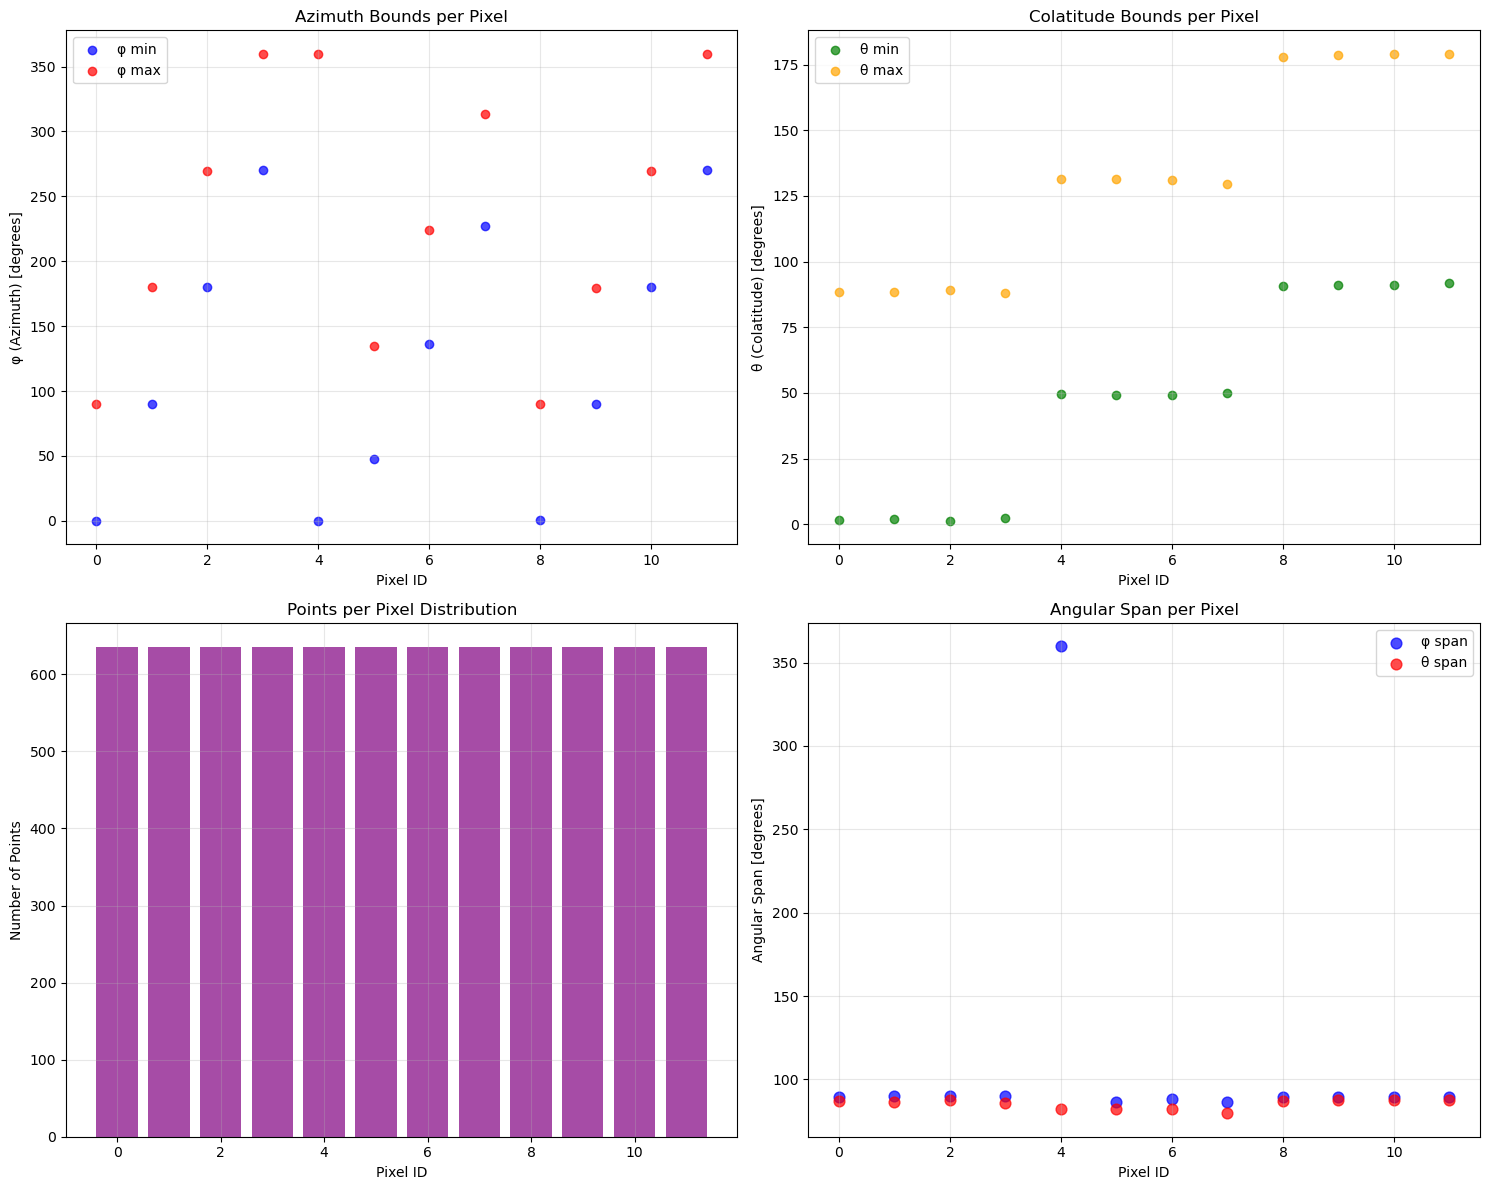


PIXEL-WISE ANALYSIS
Pixel with most points: 0 (635 points)
Pixel with fewest points: 0 (635 points)

Largest φ span: Pixel 4 (359.79°)
Smallest φ span: Pixel 7 (86.33°)

Largest θ span: Pixel 2 (87.80°)
Smallest θ span: Pixel 7 (79.62°)

Pixels covering wide φ range (>10°): [0, 1, 10, 11, 2, 3, 4, 5, 6, 7, 8, 9]
Pixels covering wide θ range (>10°): [0, 1, 10, 11, 2, 3, 4, 5, 6, 7, 8, 9]


In [12]:
# Create a visual summary of bounds for each pixel
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# Extract data for plotting
pixel_ids = [s['pixel_id'] for s in file_summaries]
phi_mins = [s['phi_range'][0] for s in file_summaries]
phi_maxs = [s['phi_range'][1] for s in file_summaries]
theta_mins = [s['theta_range'][0] for s in file_summaries]
theta_maxs = [s['theta_range'][1] for s in file_summaries]
point_counts = [s['num_points'] for s in file_summaries]

# Plot 1: Phi (azimuth) bounds per pixel
ax1.scatter(pixel_ids, phi_mins, color='blue', alpha=0.7, label='φ min')
ax1.scatter(pixel_ids, phi_maxs, color='red', alpha=0.7, label='φ max')
ax1.set_xlabel('Pixel ID')
ax1.set_ylabel('φ (Azimuth) [degrees]')
ax1.set_title('Azimuth Bounds per Pixel')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Theta (colatitude) bounds per pixel
ax2.scatter(pixel_ids, theta_mins, color='green', alpha=0.7, label='θ min')
ax2.scatter(pixel_ids, theta_maxs, color='orange', alpha=0.7, label='θ max')
ax2.set_xlabel('Pixel ID')
ax2.set_ylabel('θ (Colatitude) [degrees]')
ax2.set_title('Colatitude Bounds per Pixel')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Points per pixel
ax3.bar(pixel_ids, point_counts, alpha=0.7, color='purple')
ax3.set_xlabel('Pixel ID')
ax3.set_ylabel('Number of Points')
ax3.set_title('Points per Pixel Distribution')
ax3.grid(True, alpha=0.3)

# Plot 4: Angular span per pixel
phi_spans = [phi_maxs[i] - phi_mins[i] for i in range(len(phi_mins))]
theta_spans = [theta_maxs[i] - theta_mins[i] for i in range(len(theta_mins))]

ax4.scatter(pixel_ids, phi_spans, color='blue', alpha=0.7, label='φ span', s=60)
ax4.scatter(pixel_ids, theta_spans, color='red', alpha=0.7, label='θ span', s=60)
ax4.set_xlabel('Pixel ID')
ax4.set_ylabel('Angular Span [degrees]')
ax4.set_title('Angular Span per Pixel')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print some interesting statistics
print("\n" + "=" * 60)
print("PIXEL-WISE ANALYSIS")
print("=" * 60)

print(f"Pixel with most points: {pixel_ids[np.argmax(point_counts)]} ({max(point_counts)} points)")
print(f"Pixel with fewest points: {pixel_ids[np.argmin(point_counts)]} ({min(point_counts)} points)")

print(f"\nLargest φ span: Pixel {pixel_ids[np.argmax(phi_spans)]} ({max(phi_spans):.2f}°)")
print(f"Smallest φ span: Pixel {pixel_ids[np.argmin(phi_spans)]} ({min(phi_spans):.2f}°)")

print(f"\nLargest θ span: Pixel {pixel_ids[np.argmax(theta_spans)]} ({max(theta_spans):.2f}°)")
print(f"Smallest θ span: Pixel {pixel_ids[np.argmin(theta_spans)]} ({min(theta_spans):.2f}°)")

# Check if any pixels have unusual distributions
print(f"\nPixels covering wide φ range (>10°): ", end="")
wide_phi_pixels = [pixel_ids[i] for i, span in enumerate(phi_spans) if span > 10]
print(wide_phi_pixels if wide_phi_pixels else "None")

print(f"Pixels covering wide θ range (>10°): ", end="")
wide_theta_pixels = [pixel_ids[i] for i, span in enumerate(theta_spans) if span > 10]
print(wide_theta_pixels if wide_theta_pixels else "None")

In [13]:
# Final summary of coordinate bounds in your requested θ(0-180°) and φ(0-360°) format
print("=" * 80)
print("FINAL COORDINATE BOUNDS SUMMARY")
print("=" * 80)
print("Based on analysis of all 12 HEALPix pixel files in nside_1/")
print()
print("YOUR REQUESTED COORDINATE SYSTEM:")
print(f"  θ (colatitude, 0°=NPole to 180°=SPole): {overall_theta_min:.2f}° to {overall_theta_max:.2f}°")
print(f"  φ (azimuth, 0° to 360°):                  {overall_phi_min:.2f}° to {overall_phi_max:.2f}°")
print()
print("COVERAGE:")
print(f"  θ spans {overall_theta_max - overall_theta_min:.2f}° out of possible 180°")
print(f"  φ spans {overall_phi_max - overall_phi_min:.2f}° out of possible 360°")
print()
print("EQUIVALENT IN STANDARD LAT/LON:")
print(f"  Latitude:  {overall_lat_min:.2f}° to {overall_lat_max:.2f}°")
print(f"  Longitude: {overall_phi_min:.2f}° to {overall_phi_max:.2f}°")
print()
print("KEY OBSERVATIONS:")
print(f"  • All 12 pixels contain exactly {point_counts[0]} sampling points each")
print(f"  • Total of {sum(point_counts)} points across all pixels")
print(f"  • Pixel 4 has the largest azimuth span ({max(phi_spans):.2f}°)")
print(f"  • Pixel 2 has the largest colatitude span ({max(theta_spans):.2f}°)")
print(f"  • All pixels span significant angular ranges (>10° in both dimensions)")
print("  • The data covers roughly the northern hemisphere and part of the southern hemisphere")

# Check the theoretical HEALPix pixel size for nside=1
expected_pixel_area = 4 * np.pi / (12 * 1**2)  # steradians
expected_pixel_size_deg = np.sqrt(expected_pixel_area) * 180/np.pi  # approximate size in degrees

print(f"\nTHEORETICAL vs ACTUAL:")
print(f"  Expected pixel size (nside=1): ~{expected_pixel_size_deg:.1f}° per pixel")
print(f"  Actual average θ span: {np.mean(theta_spans):.1f}°")
print(f"  Actual average φ span: {np.mean(phi_spans):.1f}°")

FINAL COORDINATE BOUNDS SUMMARY
Based on analysis of all 12 HEALPix pixel files in nside_1/

YOUR REQUESTED COORDINATE SYSTEM:
  θ (colatitude, 0°=NPole to 180°=SPole): 1.25° to 179.19°
  φ (azimuth, 0° to 360°):                  0.02° to 359.94°

COVERAGE:
  θ spans 177.93° out of possible 180°
  φ spans 359.91° out of possible 360°

EQUIVALENT IN STANDARD LAT/LON:
  Latitude:  -89.19° to 88.75°
  Longitude: 0.02° to 359.94°

KEY OBSERVATIONS:
  • All 12 pixels contain exactly 635 sampling points each
  • Total of 7620 points across all pixels
  • Pixel 4 has the largest azimuth span (359.79°)
  • Pixel 2 has the largest colatitude span (87.80°)
  • All pixels span significant angular ranges (>10° in both dimensions)
  • The data covers roughly the northern hemisphere and part of the southern hemisphere

THEORETICAL vs ACTUAL:
  Expected pixel size (nside=1): ~58.6° per pixel
  Actual average θ span: 85.2°
  Actual average φ span: 111.5°
